In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

GPU available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

drive_path = "/content/drive/MyDrive/PPE_GPU_Project"

print("Files in PPE_GPU_Project:")
for item in os.listdir(drive_path):
    print(item)

Files in PPE_GPU_Project:
PPE Kit Detection.yolov8 (1).zip


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/PPE_GPU_Project/PPE Kit Detection.yolov8 (1).zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

print("Total files in ZIP:", len(files))

print("\nFirst 30 files:")
for f in files[:30]:
    print(f)

Total files in ZIP: 1004

First 30 files:
train/images/image382_jpg.rf.5sfag0YW8Hp8PuLIJwsD.jpg
train/images/ppe_1223_jpg.rf.jlp20yPT4eVaruPtUOE4.jpg
train/images/image781_jpg.rf.5t3DxrPVLtImwDhZXFpQ.jpg
train/images/image1115_jpg.rf.0U9eq5AggHoxBKTQfn4f.jpg
train/images/ppe_1200_jpg.rf.gEEm4YEerA9XPOWZgQfo.jpg
train/images/ppe_1283_jpg.rf.lSzo8LCawO5R0Kusum0A.jpg
train/images/youtube-64_jpg.rf.lgSk53all8CyVgNLNPMc.jpg
train/images/ppe_1150_jpg.rf.mkWHhbcfkJtPww5mJAUt.jpg
train/images/image562_jpg.rf.2l9d0zeBaYbX1RaKifGD.jpg
train/images/image500_jpg.rf.6MLCZq1eFh4ysrG8hZwP.jpg
train/images/ppe_1260_jpg.rf.pEUdb8kmRjWv7zIeJwhC.jpg
train/images/PPE_violation_cap_Person1600_Frame86612_2025-07-14_15-32-10_jpg.rf.HEudMYzqGRRwxq1RnImw.jpg
train/images/image491_jpg.rf.7Mm7xGmcQZV2VWl17jgs.jpg
train/images/youtube-186_jpg.rf.tkg4Tkbc3yXC7VXka1mI.jpg
train/images/image227_jpg.rf.B1AVxigTAMwginSv0nAU.jpg
train/images/helmet_jacket_09016_jpg.rf.8nBSkL9S47qNoNfBIoBE.jpg
train/images/image_26_jpg.

In [ ]:
import zipfile
import os
from collections import Counter

zip_path = "/content/drive/MyDrive/PPE_GPU_Project/PPE Kit Detection.yolov8 (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()

# Count images in each split
for split in ["train", "valid", "test"]:
    image_count = sum(
        1 for f in names
        if f.startswith(f"{split}/images/")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    )
    label_count = sum(
        1 for f in names
        if f.startswith(f"{split}/labels/")
        and f.lower().endswith(".txt")
    )

    print(f"{split}: {image_count} images, {label_count} labels")

train: 406 images, 406 labels
valid: 94 images, 94 labels
test: 0 images, 0 labels


In [ ]:
import yaml

with zipfile.ZipFile(zip_path, "r") as z:
    yaml_files = [f for f in z.namelist() if f.endswith(".yaml") or f.endswith(".yml")]

    print("YAML files found:", yaml_files)

    for yaml_file in yaml_files:
        print("\n---", yaml_file, "---")
        content = z.read(yaml_file).decode("utf-8")
        print(content)

YAML files found: ['data.yaml', 'data.yaml']

--- data.yaml ---
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['helmet', 'person', 'safety_vest']

roboflow:
  workspace: truptis-workspace-2hfl9
  project: ppe-kit-detection-8qwvy
  version: dataset
  license: CC BY 4.0
  url: https://universe.roboflow.com/truptis-workspace-2hfl9/ppe-kit-detection-8qwvy/dataset/dataset

--- data.yaml ---
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['helmet', 'person', 'safety_vest']

roboflow:
  workspace: truptis-workspace-2hfl9
  project: ppe-kit-detection-8qwvy
  version: dataset
  license: CC BY 4.0
  url: https://universe.roboflow.com/truptis-workspace-2hfl9/ppe-kit-detection-8qwvy/dataset/dataset


In [ ]:
import zipfile
from collections import Counter

zip_path = "/content/drive/MyDrive/PPE_GPU_Project/PPE Kit Detection.yolov8 (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:

    for split in ["train", "valid"]:
        counter = Counter()

        label_files = [
            f for f in z.namelist()
            if f.startswith(f"{split}/labels/")
            and f.endswith(".txt")
        ]

        for label_file in label_files:
            content = z.read(label_file).decode("utf-8").strip()

            if content:
                for line in content.splitlines():
                    class_id = int(line.split()[0])
                    counter[class_id] += 1

        print(f"\n{split.upper()}")
        print("helmet      :", counter[0])
        print("person      :", counter[1])
        print("safety_vest :", counter[2])
        print("total objects:", sum(counter.values()))


TRAIN
helmet      : 498
person      : 1137
safety_vest : 1009
total objects: 2644

VALID
helmet      : 122
person      : 245
safety_vest : 213
total objects: 580


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/PPE_GPU_Project/PPE Kit Detection.yolov8 (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    valid_images = [
        f for f in z.namelist()
        if f.startswith("valid/images/")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

print("Validation images:", len(valid_images))

for f in valid_images:
    print(f)

Validation images: 94
valid/images/helmet_jacket_09253_jpg.rf.hq13IN1f4pzgIUHs5oZT.jpg
valid/images/image_226_jpg.rf.79Cv5RA34X68m5yGhu1M.jpg
valid/images/image_217_jpg.rf.GrlwDBUt6hIVfLb5nMWj.jpg
valid/images/vlc-record-2025-07-02-14h32m48s-rtsp___172_16_13_215-_frame_000030_jpg.rf.ImsajnvejfzkKaRzJ955.jpg
valid/images/helmet_jacket_01709_jpg.rf.YUkUML5VHf4tpAuOqhQ0.jpg
valid/images/image_112_jpg.rf.Oz7mAY9pUEWE7WEKJmbi.jpg
valid/images/vlc-record-2025-07-02-14h30m56s-rtsp___172_16_13_99-_frame_000360_jpg.rf.KOw2KRuN49KWHD5plpt1.jpg
valid/images/helmet_jacket_08379_jpg.rf.65fDQIYGo7eT4eQ0wmiK.jpg
valid/images/helmet_jacket_00969_jpg.rf.CXEJUGI3J2NdAAr0IJXp.jpg
valid/images/vlc-record-2025-07-02-14h27m44s-rtsp___172_16_13_215-_frame_000660_jpg.rf.91iqka3dTc3YQpwZnsFJ.jpg
valid/images/ppe_1007_jpg.rf.kcxuqm0Z1zjM6Ww7k5sk.jpg
valid/images/image_24_jpg.rf.RkCE4QzKLhJvUtYnq7JP.jpg
valid/images/vlc-record-2025-07-03-10h03m28s-rtsp___172_16_13_215-_frame_000090_jpg.rf.As3Vr9um2TF2JSU2QZ9p.jp

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/PPE_GPU_Project/PPE Kit Detection.yolov8 (1).zip"
extract_path = "/content/PPE_raw"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")
print("\nContents:")
for item in os.listdir(extract_path):
    print(item)

Dataset extracted successfully.

Contents:
data.yaml
train
valid
README.dataset.txt
README.roboflow.txt


In [ ]:
import os
from collections import Counter

train_dir = "/content/PPE_raw/train/images"
valid_dir = "/content/PPE_raw/valid/images"

train_files = [
    f for f in os.listdir(train_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

valid_files = [
    f for f in os.listdir(valid_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Train images:", len(train_files))
print("Valid images:", len(valid_files))
print("Total images:", len(train_files) + len(valid_files))

# Identify common source types
def source_type(filename):
    if filename.startswith("vlc-record"):
        return "VLC video frames"
    elif filename.startswith("PPE_violation"):
        return "PPE violation video frames"
    elif filename.startswith("youtube"):
        return "YouTube"
    elif filename.startswith("helmet_jacket"):
        return "helmet_jacket"
    elif filename.startswith("ppe_"):
        return "ppe"
    elif filename.startswith("image"):
        return "image"
    elif filename.startswith("pos_"):
        return "pos"
    else:
        return "other"

all_files = train_files + valid_files
counts = Counter(source_type(f) for f in all_files)

print("\nSource types:")
for source, count in counts.items():
    print(f"{source}: {count}")

Train images: 406
Valid images: 94
Total images: 500

Source types:
ppe: 166
PPE violation video frames: 50
VLC video frames: 147
YouTube: 16
image: 75
helmet_jacket: 38
pos: 8


In [ ]:
import os
from collections import Counter

train_dir = "/content/PPE_raw/train/images"
valid_dir = "/content/PPE_raw/valid/images"

all_files = [
    f for f in os.listdir(train_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
] + [
    f for f in os.listdir(valid_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

def get_source_group(filename):
    name = filename

    # Remove Roboflow extension
    if ".rf." in name:
        name = name.split(".rf.")[0]

    # Group video frames by source recording
    if "_frame_" in name:
        return name.split("_frame_")[0]

    # Other images remain individual groups
    return name

groups = Counter(get_source_group(f) for f in all_files)

print("Total unique source groups:", len(groups))
print("\nLargest source groups:")

for group, count in groups.most_common(20):
    print(f"{count:3d} images -> {group}")

Total unique source groups: 370

Largest source groups:
 20 images -> vlc-record-2025-07-03-10h05m21s-rtsp___172_16_13_215-
 18 images -> vlc-record-2025-07-03-10h03m28s-rtsp___172_16_13_215-
 12 images -> vlc-record-2025-07-14-10h33m28s-rtsp___172_16_13_219-
 12 images -> vlc-record-2025-07-03-10h06m29s-rtsp___172_16_13_215-
 12 images -> vlc-record-2025-07-02-14h30m56s-rtsp___172_16_13_99-
 10 images -> vlc-record-2025-07-01-16h57m22s-rtsp___172_16_13_215-
 10 images -> vlc-record-2025-07-01-16h55m49s-rtsp___172_16_13_215-
  9 images -> vlc-record-2025-07-02-14h20m41s-rtsp___172_16_13_215-
  8 images -> vlc-record-2025-07-02-14h26m07s-rtsp___172_16_13_215-
  6 images -> vlc-record-2025-07-02-14h16m59s-rtsp___172_16_13_215-
  5 images -> vlc-record-2025-07-02-14h27m44s-rtsp___172_16_13_215-
  4 images -> vlc-record-2025-07-14-10h26m33s-rtsp___172_16_13_219-
  4 images -> vlc-record-2025-07-01-14h43m41s-rtsp___172_16_13_99-
  4 images -> vlc-record-2025-07-02-12h27m26s-rtsp___172_16_13

In [ ]:
import os
import shutil
import random
from collections import defaultdict, Counter

# =========================
# Paths
# =========================

raw_root = "/content/PPE_raw"
output_root = "/content/PPE_GPU"

train_img_src = os.path.join(raw_root, "train", "images")
train_lbl_src = os.path.join(raw_root, "train", "labels")

valid_img_src = os.path.join(raw_root, "valid", "images")
valid_lbl_src = os.path.join(raw_root, "valid", "labels")

# Start clean
if os.path.exists(output_root):
    shutil.rmtree(output_root)

# Create folders
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(output_root, "images", split), exist_ok=True)
    os.makedirs(os.path.join(output_root, "labels", split), exist_ok=True)

# =========================
# Collect all image-label pairs
# =========================

pairs = []

for img_dir, lbl_dir in [
    (train_img_src, train_lbl_src),
    (valid_img_src, valid_lbl_src)
]:
    for filename in os.listdir(img_dir):

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        image_path = os.path.join(img_dir, filename)

        base = os.path.splitext(filename)[0]
        label_path = os.path.join(lbl_dir, base + ".txt")

        if not os.path.exists(label_path):
            print("WARNING: Missing label:", filename)
            continue

        pairs.append((filename, image_path, label_path))

print("Image-label pairs found:", len(pairs))

# =========================
# Create source groups
# =========================

def get_source_group(filename):

    name = filename

    # Remove Roboflow suffix
    if ".rf." in name:
        name = name.split(".rf.")[0]

    # Video frames:
    # everything before _frame_ belongs to same source video
    if "_frame_" in name:
        return name.split("_frame_")[0]

    # Non-video images remain individual groups
    return name


groups = defaultdict(list)

for filename, image_path, label_path in pairs:
    group = get_source_group(filename)
    groups[group].append((filename, image_path, label_path))

print("Unique source groups:", len(groups))

# =========================
# Shuffle groups
# =========================

random.seed(42)

group_items = list(groups.items())
random.shuffle(group_items)

# =========================
# Assign groups using target
# =========================

targets = {
    "train": 0.80,
    "val": 0.10,
    "test": 0.10
}

split_groups = {
    "train": [],
    "val": [],
    "test": []
}

split_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

total_images = len(pairs)

for group_name, group_files in group_items:

    group_size = len(group_files)

    # Choose split whose current count is furthest below its target
    scores = {}

    for split in ["train", "val", "test"]:
        target_count = total_images * targets[split]
        scores[split] = target_count - split_counts[split]

    chosen_split = max(scores, key=scores.get)

    split_groups[chosen_split].append((group_name, group_files))
    split_counts[chosen_split] += group_size

# =========================
# Copy files
# =========================

for split in ["train", "val", "test"]:

    for group_name, group_files in split_groups[split]:

        for filename, image_path, label_path in group_files:

            shutil.copy2(
                image_path,
                os.path.join(output_root, "images", split, filename)
            )

            shutil.copy2(
                label_path,
                os.path.join(
                    output_root,
                    "labels",
                    split,
                    os.path.basename(label_path)
                )
            )

# =========================
# Create data.yaml
# =========================

yaml_content = """path: /content/PPE_GPU
train: images/train
val: images/val
test: images/test

nc: 3
names:
  0: helmet
  1: person
  2: safety_vest
"""

with open(os.path.join(output_root, "data.yaml"), "w") as f:
    f.write(yaml_content)

# =========================
# Final counts
# =========================

print("\n========== FINAL DATASET ==========")

for split in ["train", "val", "test"]:

    img_dir = os.path.join(output_root, "images", split)

    count = len([
        f for f in os.listdir(img_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"{split.upper():5s}: {count} images")

print("\nDataset created at:")
print(output_root)

Image-label pairs found: 500
Unique source groups: 370

========== FINAL DATASET ==========
TRAIN: 400 images
VAL  : 50 images
TEST : 50 images

Dataset created at:
/content/PPE_GPU


In [ ]:
from collections import Counter
import os

dataset_root = "/content/PPE_GPU"

class_names = {
    0: "helmet",
    1: "person",
    2: "safety_vest"
}

for split in ["train", "val", "test"]:

    label_dir = os.path.join(dataset_root, "labels", split)

    counts = Counter()

    for filename in os.listdir(label_dir):

        if not filename.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, filename), "r") as f:
            for line in f:
                line = line.strip()

                if line:
                    class_id = int(line.split()[0])
                    counts[class_id] += 1

    print(f"\n{split.upper()}")
    print("-" * 30)

    for class_id, name in class_names.items():
        print(f"{name:12s}: {counts[class_id]}")

    print("Total objects:", sum(counts.values()))


TRAIN
------------------------------
helmet      : 502
person      : 1093
safety_vest : 989
Total objects: 2584

VAL
------------------------------
helmet      : 38
person      : 140
safety_vest : 114
Total objects: 292

TEST
------------------------------
helmet      : 80
person      : 149
safety_vest : 119
Total objects: 348


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 9.4 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.173


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
from ultralytics import YOLO
import os

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

# Train on your 500-image PPE dataset
results = model.train(
    data="/content/PPE_GPU/data.yaml",
    epochs=80,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,

    # Save results directly to Google Drive
    project="/content/drive/MyDrive/PPE_GPU_Project",
    name="ppe_yolov8n_gpu",

    # Stop if validation does not improve
    patience=15,

    # Save checkpoints
    save=True,

    # Use pretrained weights
    pretrained=True
)

print("Training completed!")

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PPE_GPU/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_yolov8n_gpu, nbs=64, nms=None, opset=None, optimize=False,

In [ ]:
from ultralytics import YOLO

# Load the best trained model
model = YOLO(
    "/content/drive/MyDrive/PPE_GPU_Project/ppe_yolov8n_gpu/weights/best.pt"
)

# Evaluate on the completely unseen TEST set
test_results = model.val(
    data="/content/PPE_GPU/data.yaml",
    split="test",
    device=0,
    imgsz=640
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1525.0±1098.0 MB/s, size: 155.3 KB)
val: Scanning /content/PPE_GPU/labels/test... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 576.6it/s 0.1s
val: New cache created: /content/PPE_GPU/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.6s/it 6.4s
                   all         50        348      0.828      0.824      0.868      0.507
                helmet         34         80      0.935      0.905      0.939      0.613
                person         50        149      0.778      0.792      0.836      0.462
           safety_vest         44        119      0.771      0.773      0.829      0.445
Speed: 18.5ms preprocess, 24.6ms inference, 0.0ms loss, 8.1ms postprocess per image
Resu

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/PPE_GPU_Project/ppe_yolov8n_gpu/weights/best.pt"
)

results = model.predict(
    source="/content/PPE_GPU/images/test",
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/PPE_GPU_Project",
    name="test_predictions"
)

print("Prediction completed!")
print("Saved to:")
print("/content/drive/MyDrive/PPE_GPU_Project/test_predictions")


image 1/50 /content/PPE_GPU/images/test/PPE_violation_cap_Person1115_Frame58216_2025-07-14_15-05-25_jpg.rf.aVyFvuQWtwgIAHFontON.jpg: 384x640 1 person, 8.4ms
image 2/50 /content/PPE_GPU/images/test/PPE_violation_cap_Person1119_Frame23938_2025-07-14_16-50-12_jpg.rf.bTbsdxSJAY9qNOYvj8nH.jpg: 384x640 3 persons, 3 safety_vests, 14.3ms
image 3/50 /content/PPE_GPU/images/test/PPE_violation_cap_Person113_Frame1600_2025-07-14_16-11-53_jpg.rf.Jk2WiWEzDvxcbI0C9zMi.jpg: 384x640 2 persons, 1 safety_vest, 9.1ms
image 4/50 /content/PPE_GPU/images/test/PPE_violation_cap_Person1169_Frame62324_2025-07-14_15-09-28_jpg.rf.85GdYHLkEgkZRBmZE2C2.jpg: 384x640 3 persons, 3 safety_vests, 9.2ms
image 5/50 /content/PPE_GPU/images/test/PPE_violation_cap_Person130_Frame4051_2025-07-14_14-15-04_jpg.rf.JaWRVNECF2p42Llr6pzd.jpg: 384x640 1 person, 9.4ms
image 6/50 /content/PPE_GPU/images/test/PPE_violation_cap_Person1324_Frame69586_2025-07-14_15-15-56_jpg.rf.CrT3vCTS3bN87eWND5zp.jpg: 384x640 1 person, 9.2ms
image 7/50

Total output images: 50
PPE_violation_cap_Person1115_Frame58216_2025-07-14_15-05-25_jpg.rf.aVyFvuQWtwgIAHFontON.jpg


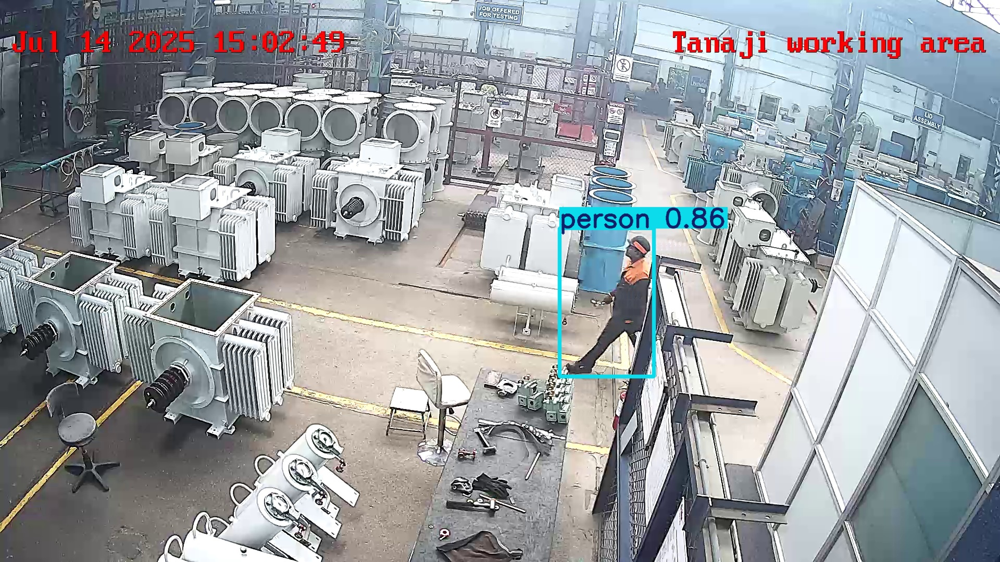

PPE_violation_cap_Person1119_Frame23938_2025-07-14_16-50-12_jpg.rf.bTbsdxSJAY9qNOYvj8nH.jpg


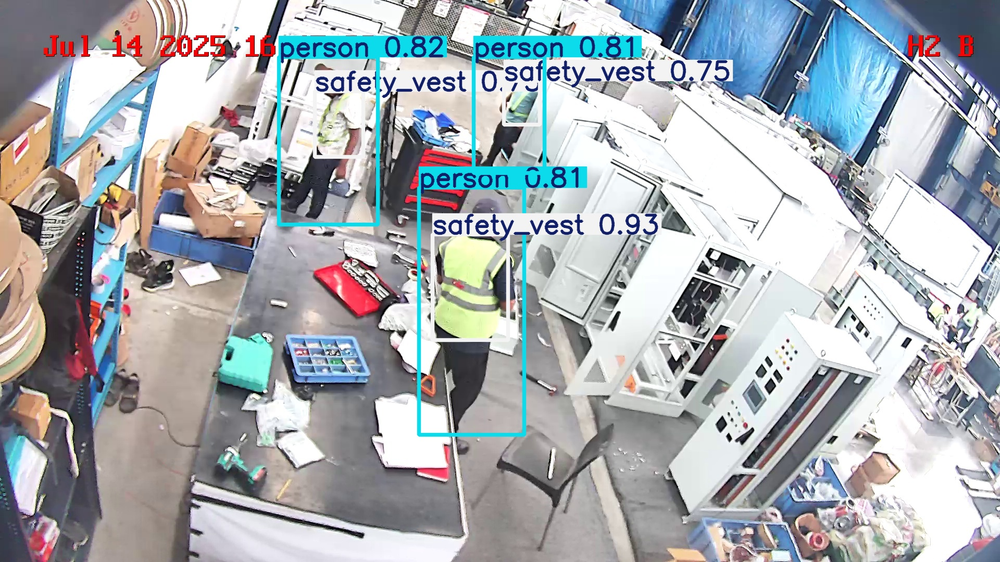

PPE_violation_cap_Person113_Frame1600_2025-07-14_16-11-53_jpg.rf.Jk2WiWEzDvxcbI0C9zMi.jpg


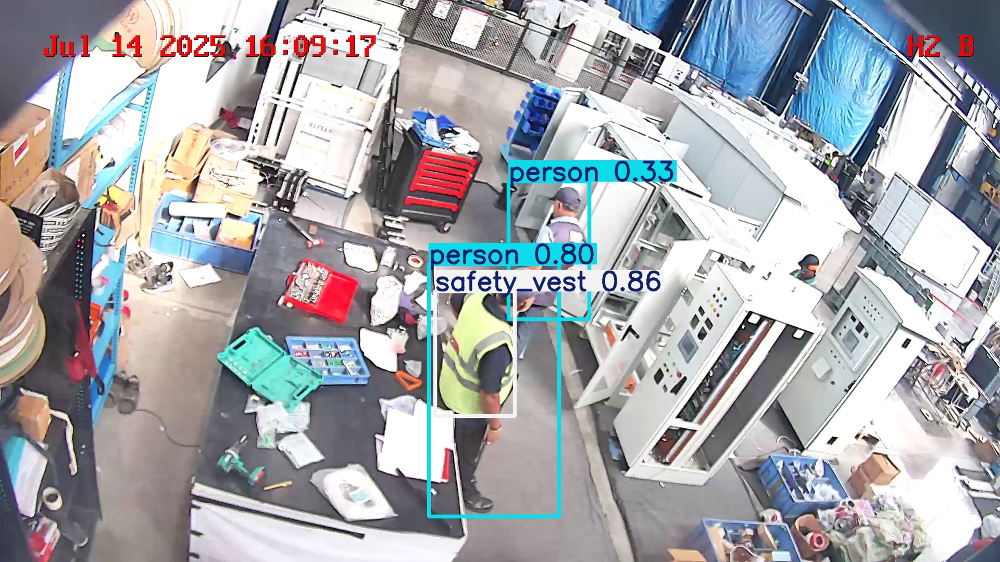

PPE_violation_cap_Person1169_Frame62324_2025-07-14_15-09-28_jpg.rf.85GdYHLkEgkZRBmZE2C2.jpg


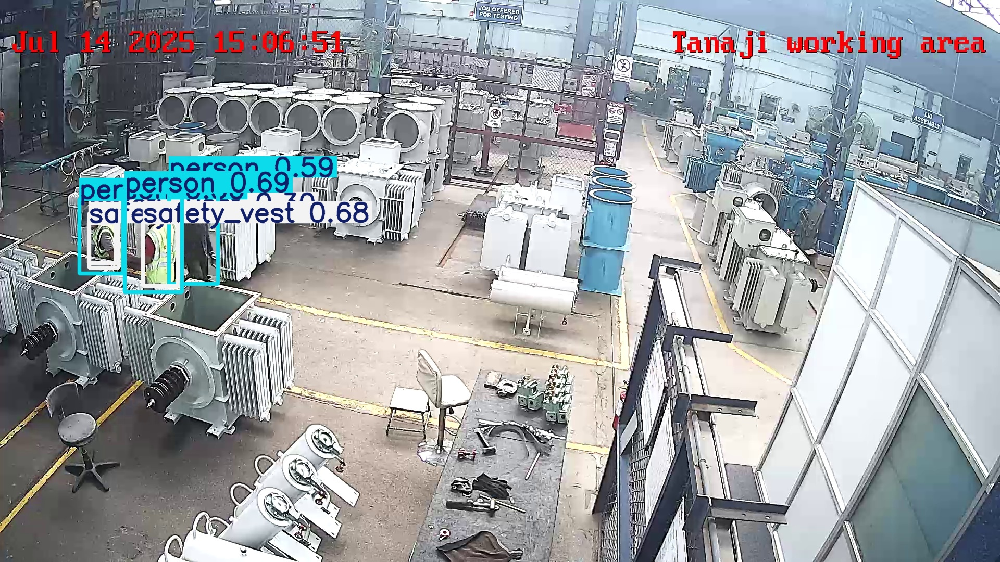

PPE_violation_cap_Person130_Frame4051_2025-07-14_14-15-04_jpg.rf.JaWRVNECF2p42Llr6pzd.jpg


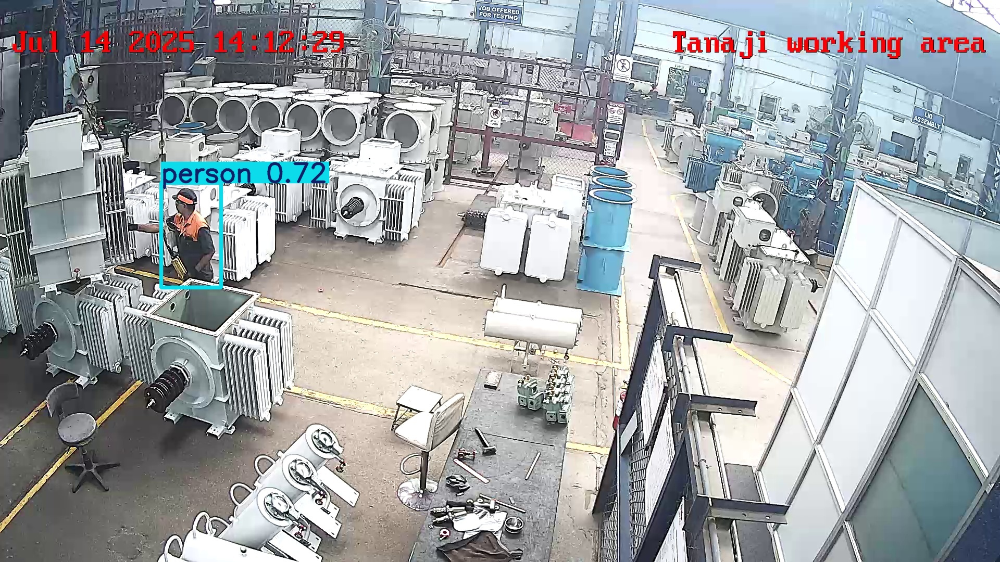

PPE_violation_cap_Person1324_Frame69586_2025-07-14_15-15-56_jpg.rf.CrT3vCTS3bN87eWND5zp.jpg


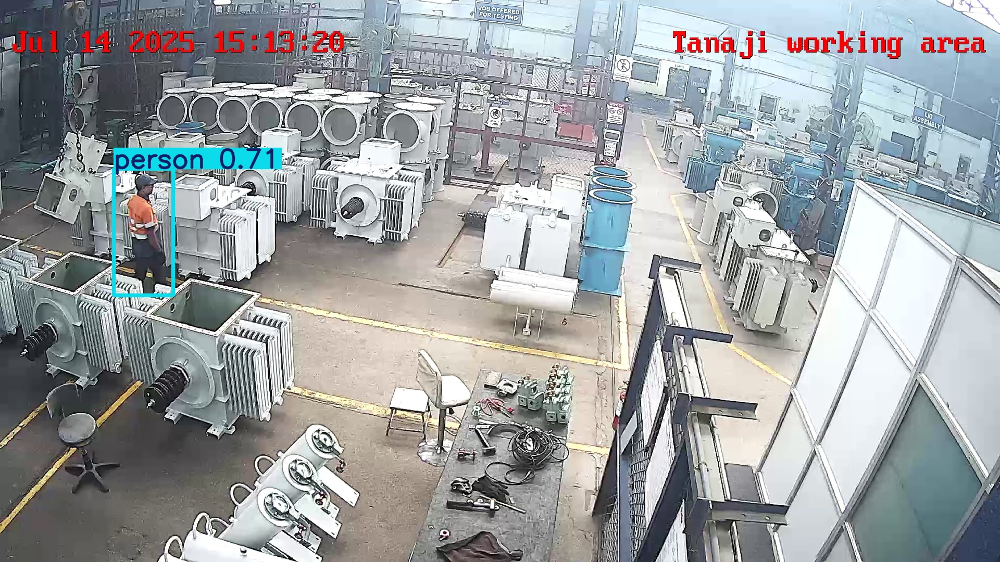

In [ ]:
from IPython.display import display
from PIL import Image
import os
import glob

output_dir = "/content/drive/MyDrive/PPE_GPU_Project/test_predictions"

images = sorted(
    glob.glob(os.path.join(output_dir, "*.jpg")) +
    glob.glob(os.path.join(output_dir, "*.png"))
)

print("Total output images:", len(images))

# Display first 6 predictions
for img_path in images[:6]:
    print(os.path.basename(img_path))
    display(Image.open(img_path))

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 474.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 10.6 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/PPE_GPU_Project/ppe_yolov8n_gpu/weights/best.pt"
)

print("✅ Model loaded successfully!")
print("Classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✅ Model loaded successfully!
Classes: {0: 'helmet', 1: 'person', 2: 'safety_vest'}


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/PPE_GPU_Project/ppe_yolov8n_gpu/weights/best.pt"
)

print("✅ Model loaded successfully!")
print("Classes:", model.names)

✅ Model loaded successfully!
Classes: {0: 'helmet', 1: 'person', 2: 'safety_vest'}


In [ ]:
from google.colab import files

print("Upload your PPE video:")
uploaded = files.upload()

video_name = next(iter(uploaded))
video_path = "/content/" + video_name

print("\n✅ Video uploaded successfully!")
print("Video:", video_name)
print("Path:", video_path)

Upload your PPE video:


Saving 8964295-uhd_3840_2160_25fps.mp4 to 8964295-uhd_3840_2160_25fps.mp4

✅ Video uploaded successfully!
Video: 8964295-uhd_3840_2160_25fps.mp4
Path: /content/8964295-uhd_3840_2160_25fps.mp4


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 10.0 MB/s eta 0:00:00


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/PPE_GPU_Project"

print("=== PPE_GPU_Project ===")

for item in sorted(os.listdir(project_path)):
    full_path = os.path.join(project_path, item)

    if os.path.isdir(full_path):
        print(f"📁 {item}/")
    else:
        print(f"📄 {item}")

=== PPE_GPU_Project ===
📄 PPE Kit Detection.yolov8 (1).zip
📁 ppe_yolov8n_gpu/
📁 test_predictions/


In [ ]:
import os

model_folder = "/content/drive/MyDrive/PPE_GPU_Project/ppe_yolov8n_gpu"

print("=== ppe_yolov8n_gpu ===")

for root, dirs, files in os.walk(model_folder):
    level = root.replace(model_folder, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}📁 {os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  📄 {file}")

=== ppe_yolov8n_gpu ===
📁 ppe_yolov8n_gpu/
  📄 args.yaml
  📄 labels.jpg
  📄 train_batch0.jpg
  📄 train_batch1.jpg
  📄 train_batch2.jpg
  📄 train_batch1750.jpg
  📄 train_batch1751.jpg
  📄 train_batch1752.jpg
  📄 val_batch0_labels.jpg
  📄 val_batch0_pred.jpg
  📄 BoxPR_curve.png
  📄 val_batch1_pred.jpg
  📄 val_batch1_labels.jpg
  📄 BoxF1_curve.png
  📄 BoxP_curve.png
  📄 BoxR_curve.png
  📄 confusion_matrix_normalized.png
  📄 confusion_matrix.png
  📄 results.png
  📄 results.csv
  📁 weights/
    📄 best.pt
    📄 last.pt


In [ ]:
from ultralytics import YOLO
import os

# Exact trained model path
model_path = "/content/drive/MyDrive/PPE_GPU_Project/ppe_yolov8n_gpu/weights/best.pt"

# Your uploaded video
video_path = "/content/5100046-uhd_3840_2160_30fps.mp4"

print("Model exists:", os.path.exists(model_path))
print("Video exists:", os.path.exists(video_path))

# Load trained model
model = YOLO(model_path)

print("✅ Model loaded")
print("Classes:", model.names)

# Run PPE detection
results = model.predict(
    source=video_path,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/PPE_GPU_Project",
    name="video_detection",
    device=0,
    verbose=True
)

print("\n✅ PPE detection completed!")
print("Output folder:")
print("/content/drive/MyDrive/PPE_GPU_Project/video_detection")

Model exists: True
Video exists: True
✅ Model loaded
Classes: {0: 'helmet', 1: 'person', 2: 'safety_vest'}

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/350) /content/5100046-uhd_3840_2160_30fps.mp4: 384x640 1 helmet, 1 person, 1 safety_vest, 8.8ms
video 1/1 (frame 2/350) /content/5100046-uhd_3840_2160_30fps.mp4: 384x640 1 helmet, 1 person, 1 safety_vest, 26.8ms
video 1/1 (frame 3/350) /content/5100046-uhd_3840_2160_30fps.mp4: 384x640 1 helmet, 1 person, 1 safety_vest, 24.6ms
video

In [ ]:
from IPython.display import Video, display
import glob
import os

output_dir = "/content/drive/MyDrive/PPE_GPU_Project/video_detection"

video_files = glob.glob(os.path.join(output_dir, "*"))

print("Files in output folder:")
for f in video_files:
    print(os.path.basename(f))

video_files = [
    f for f in video_files
    if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
]

if video_files:
    print("\n✅ Output video found!")
    display(Video(video_files[0], embed=True))
else:
    print("❌ Output video not found.")

Files in output folder:
5100046-uhd_3840_2160_30fps.avi

✅ Output video found!
Buffered data was truncated after reaching the output size limit.

In [ ]:
import subprocess
import os

input_video = "/content/drive/MyDrive/PPE_GPU_Project/video_detection/5100046-uhd_3840_2160_30fps.avi"
output_video = "/content/drive/MyDrive/PPE_GPU_Project/video_detection/PPE_detection_preview.mp4"

print("Creating compressed preview...")

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", input_video,
    "-vf", "scale=1280:-2",
    "-c:v", "libx264",
    "-preset", "fast",
    "-crf", "28",
    "-c:a", "aac",
    output_video
], check=True)

print("✅ Preview created!")
print("Saved to:")
print(output_video)

print("File size:",
      round(os.path.getsize(output_video) / (1024*1024), 2),
      "MB")

Creating compressed preview...
✅ Preview created!
Saved to:
/content/drive/MyDrive/PPE_GPU_Project/video_detection/PPE_detection_preview.mp4
File size: 1.18 MB


In [ ]:
from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/PPE_GPU_Project/ppe_yolov8n_gpu/weights/best.pt"
video_path = "/content/8965526-uhd_2160_3840_25fps.mp4"

print("Model exists:", os.path.exists(model_path))
print("Video exists:", os.path.exists(video_path))

model = YOLO(model_path)

print("✅ Model loaded")
print("Classes:", model.names)

results = model.predict(
    source=video_path,
    conf=0.25,
    save=True,
    project="/content/drive/MyDrive/PPE_GPU_Project",
    name="video_detection_8965526",
    device=0,
    verbose=True
)

print("\n✅ PPE detection completed!")
print("Output folder:")
print("/content/drive/MyDrive/PPE_GPU_Project/video_detection_8965526")

Model exists: True
Video exists: True
✅ Model loaded
Classes: {0: 'helmet', 1: 'person', 2: 'safety_vest'}

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/315) /content/8965526-uhd_2160_3840_25fps.mp4: 640x384 2 helmets, 2 persons, 2 safety_vests, 8.6ms
video 1/1 (frame 2/315) /content/8965526-uhd_2160_3840_25fps.mp4: 640x384 2 helmets, 2 persons, 2 safety_vests, 12.1ms
video 1/1 (frame 3/315) /content/8965526-uhd_2160_3840_25fps.mp4: 640x384 2 helmets, 2 persons, 2 safety_vests, 23.

In [ ]:
from IPython.display import Video

output_video = "/content/drive/MyDrive/PPE_GPU_Project/video_detection_8965526/PPE_detection_final.mp4"

Video(output_video, embed=True, width=900)